# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import L7IrishDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor
from aitlas.utils import image_loader
import csv

## Visualize images and masks

Total number of patches: 206


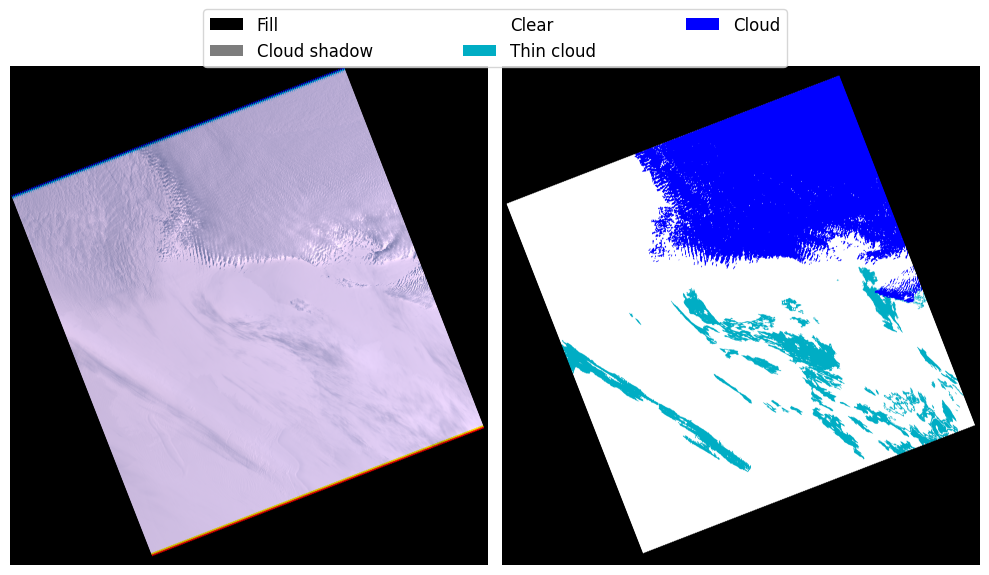

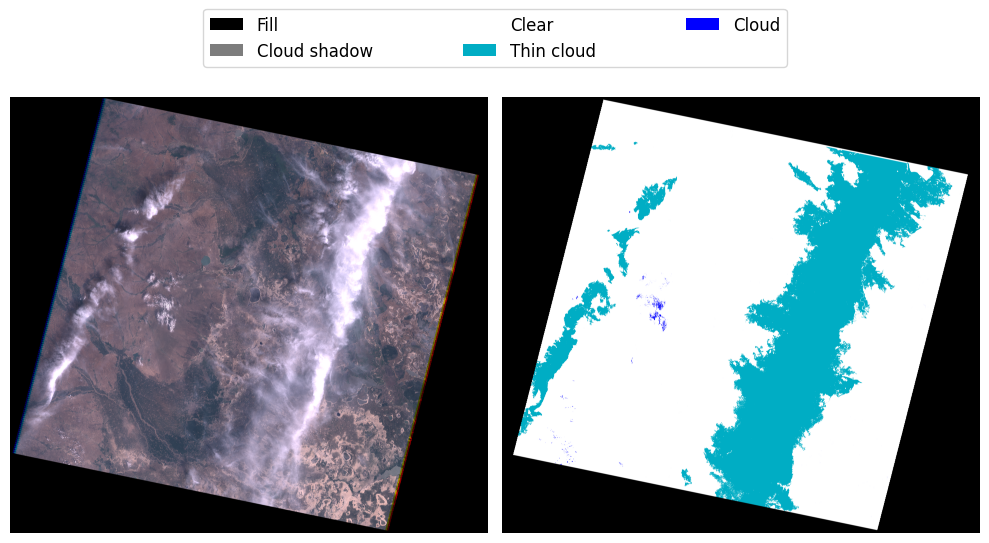

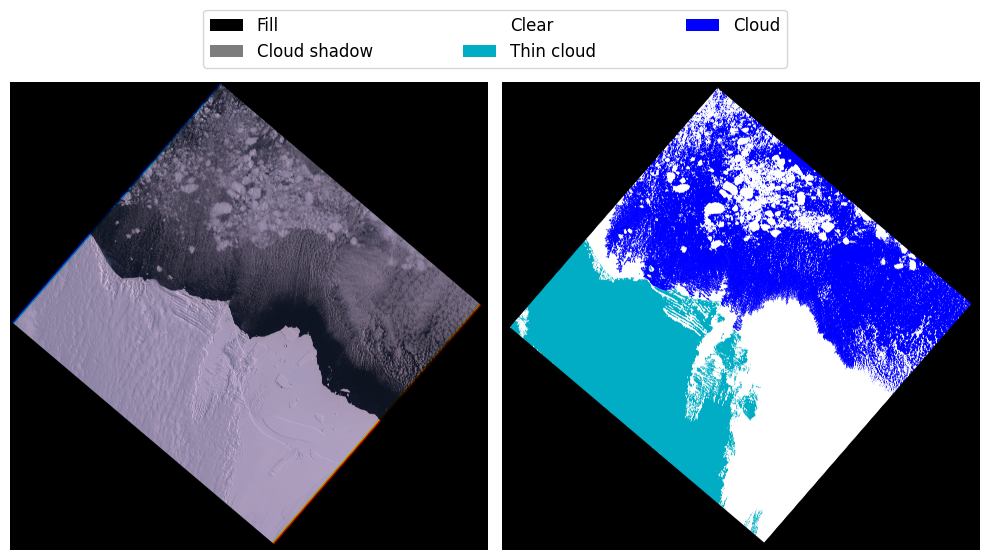

In [ ]:
dataset_config = {
    "data_dir": "./data/l7irish"
}
dataset = L7IrishDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [8]:
dataset.data_distribution_table()

,Number of pixels
Fill,4.557502e+09
Cloud shadow,5.324152e+07
Clear,5.231764e+09
Thin cloud,8.104168e+08
Cloud,1.817959e+09


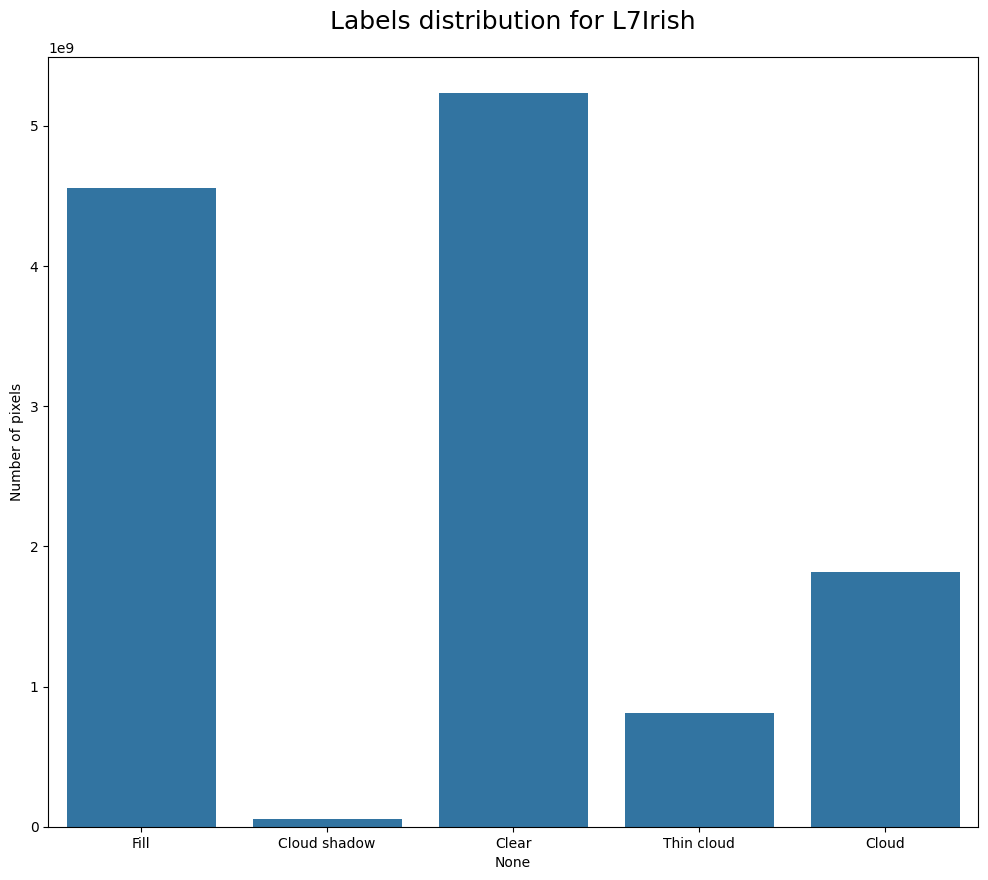

In [9]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/l7irish",
    "csv_file": "./data/l7irish/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = L7IrishDataset(train_dataset_config)
len(train_dataset)

166

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/l7irish"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [12]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-08 06:42:53,571 INFO Starting training.
training: 100%|██████████| 21/21 [5:03:20<00:00, 866.67s/it]   
2025-05-08 11:46:13,784 INFO epoch: 1, time: 18200, loss:  0.63132
testing on train set: 100%|██████████| 21/21 [5:03:56<00:00, 868.39s/it]  
2025-05-08 16:50:11,755 INFO IOU:0.5358538959656933, IOU mean:0.35927473081453465, IOU per Class:[0.87114634 0.         0.61039571 0.06880992 0.24602168]
training: 100%|██████████| 21/21 [5:06:12<00:00, 874.90s/it]   
2025-05-08 21:56:24,697 INFO epoch: 2, time: 18373, loss:  0.53364
testing on train set: 100%|██████████| 21/21 [5:00:16<00:00, 857.91s/it]  
2025-05-09 02:56:40,834 INFO IOU:0.5634251043848512, IOU mean:0.3743607044538012, IOU per Class:[0.89161929 0.         0.65484893 0.07244445 0.25289085]
training: 100%|██████████| 21/21 [5:03:36<00:00, 867.46s/it]   
2025-05-09 08:00:17,463 INFO epoch: 3, time: 18217, loss:  0.49562
testing on train set: 100%|██████████| 21/21 [5:13:21<00:00, 895.32s/it]   
2025-05-09 13:13:39,230 IN

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/l7irish",
    "csv_file": "./data/l7irish/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = L7IrishDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/l7irish/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

20


2025-05-13 08:48:32,393 INFO Loading checkpoint /home/dragik/data/FAIR_EO/l7irish/checkpoint.pth.tar
2025-05-13 08:48:38,879 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/l7irish/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 5/5 [51:13<00:00, 614.74s/it]   


[{'IOU': 0.6556096508585625,
  'IOU mean': 0.396014870256901,
  'IOU per Class': array([0.91288105, 0.        , 0.6539737 , 0.03713786, 0.37608174])}]

## Predictions

2025-05-13 11:49:20,038 INFO Loading checkpoint /home/dragik/data/FAIR_EO/l7irish/checkpoint.pth.tar
2025-05-13 11:49:20,419 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/l7irish/checkpoint.pth.tar at epoch 11


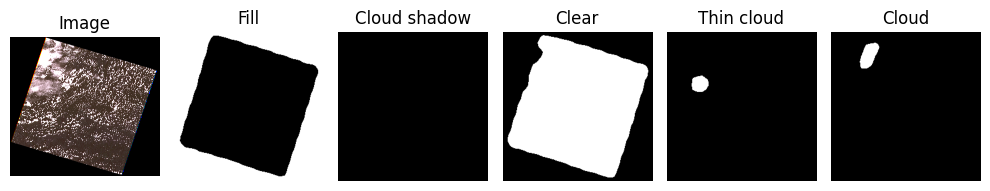

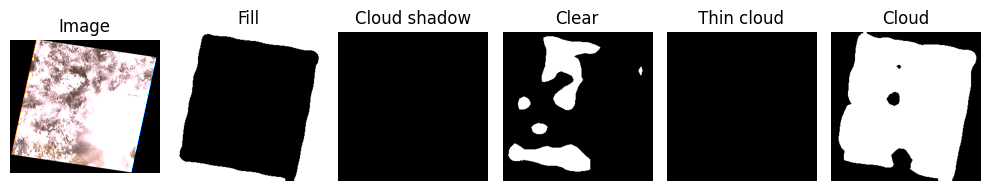

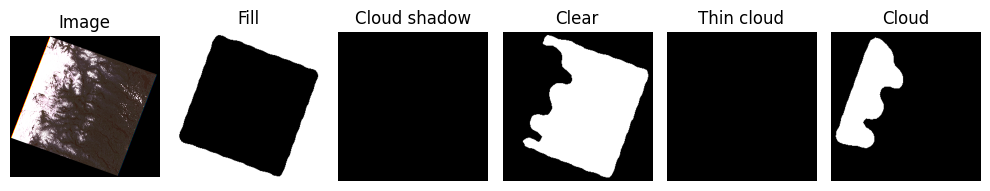

In [ ]:
model_path = "./data/l7irish/checkpoint.pth.tar"
labels = ["Fill","Cloud shadow","Clear","Thin cloud","Cloud"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "./data/l7irish/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/l7irish/' + test_list[0])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/l7irish/' + test_list[1])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/l7irish/' + test_list[10])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)